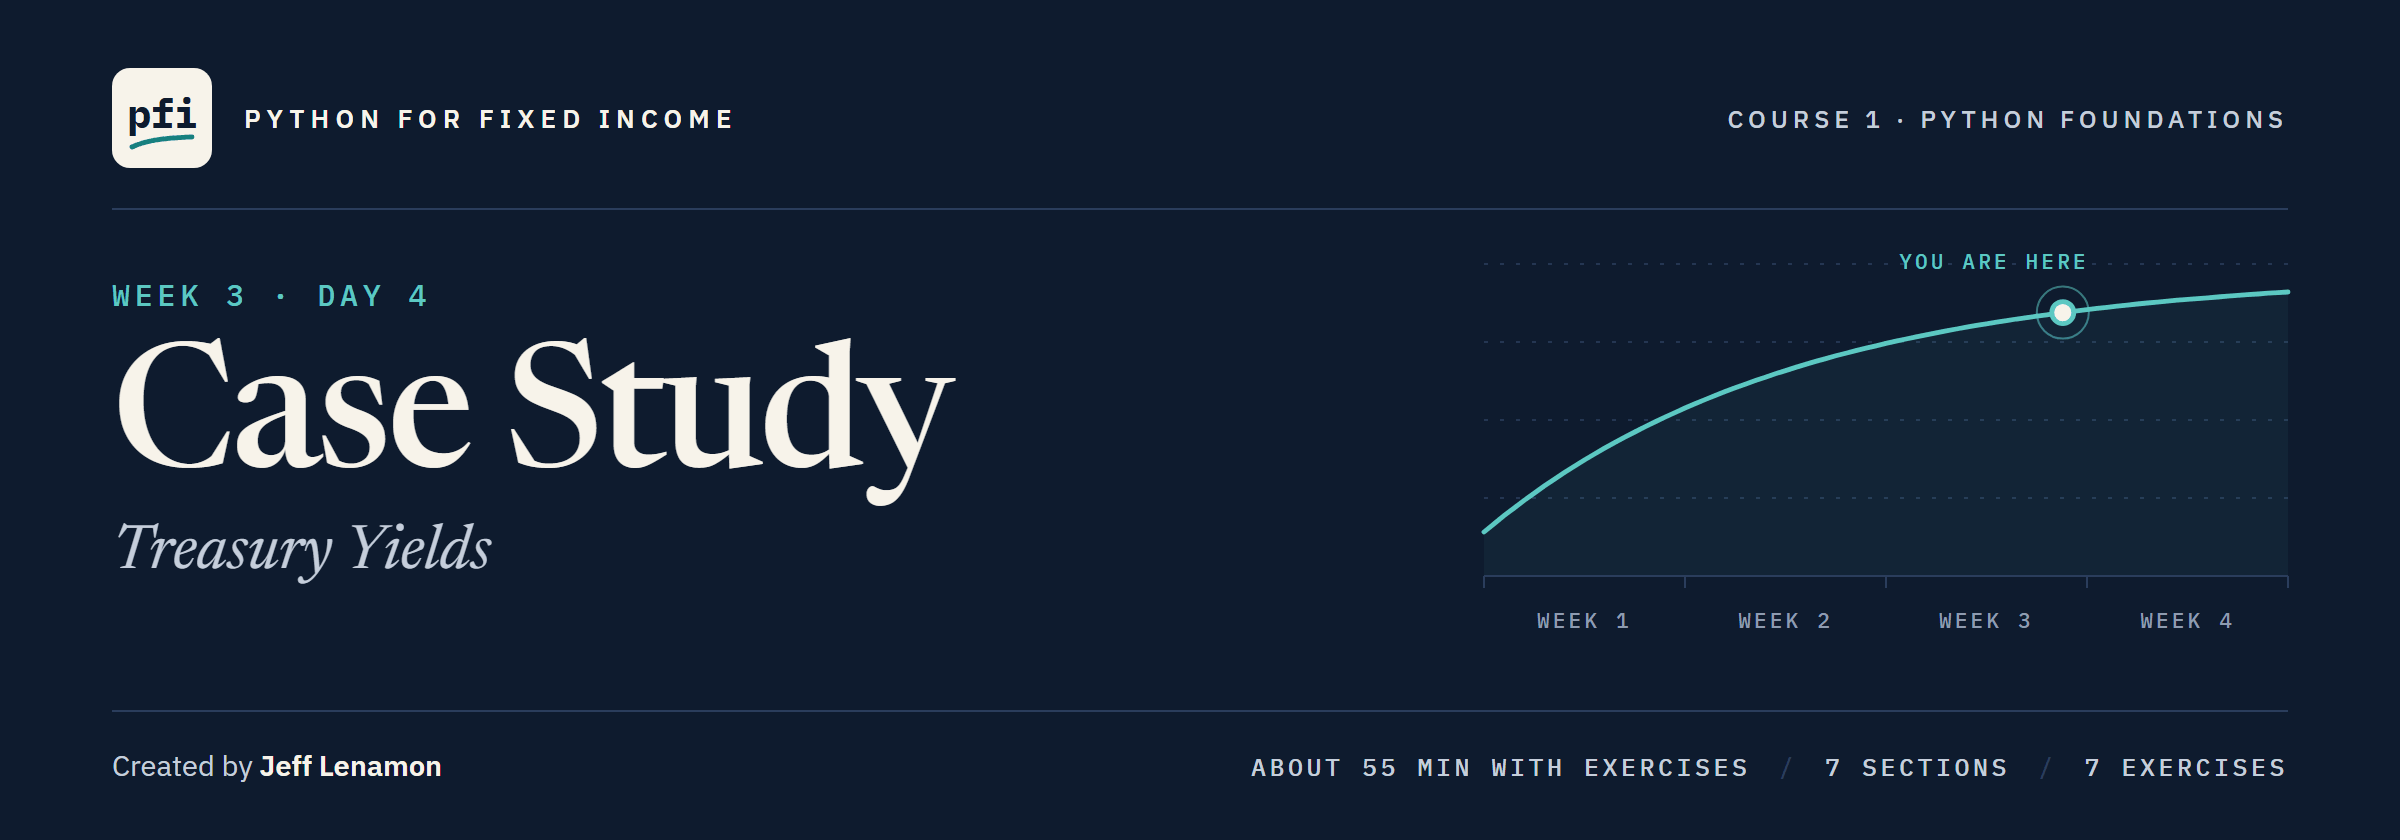

# Case Study: Treasury Yields

Week 3, Day 4. Daily Treasury par yields from 2015 to 2026 are loaded as a time series and described by tenor, by year, and day by day.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day4/14_case_study_treasury_yields.ipynb)

## Problem Definition

### Context

The desk lead's nineteenth note:

> Our investment grade bonds are quoted over Treasuries, and the desk's Treasury sheet is stale. Rebuild it from Treasury's own file, so it reruns on every download. Tell me what the file covers and what is missing, where each tenor has been by year, what the curve looked like, the 10s less 2s spread and how long it stayed below zero, and how much yields move in a day. Describe it: no why, no forecast.

The course's first real file: the portfolio is invented, these yields are Treasury's.

### Objective

You are the desk's analyst.

Answer seven questions:

1. What dates are covered, and what is missing?
2. Which tenors start late, and when?
3. Where was each tenor, year by year?
4. When was each tenor at its high and low?
5. What did the curve look like on chosen dates?
6. How often was 10 Yr less 2 Yr below zero?
7. How large are the daily changes?

### The Data

<table align="left">
<tr><th align="left"></th><th align="left"></th></tr>
<tr><td align="left">Source</td><td align="left">U.S. Department of the Treasury, <a href="https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve">Daily Treasury Par Yield Curve Rates</a></td></tr>
<tr><td align="left">Retrieved</td><td align="left">2026-10-03</td></tr>
<tr><td align="left">Span</td><td align="left">2015-01-02 to 2026-10-02</td></tr>
<tr><td align="left">File</td><td align="left"><code>treasury_par_yields.csv</code> in <code>data</code>, built by <code>tools/get_treasury_yields.py</code></td></tr>
</table>
<br clear="left">

As published: nothing filled or removed; only the layout changed, dates oldest first.
Treasury builds these [par yields](https://home.treasury.gov/policy-issues/financing-the-government/interest-rate-statistics) from closing bid prices on the most recently auctioned securities.

Columns: `date`, then fourteen tenors from `1 Mo` to `30 Yr`; `1.5 Month` is Treasury's own label.
**Yields in percent; spreads and daily changes in basis points, the difference in percent times 100.**

### How We Will Work

We follow the EDA notebook's order: check the file, then one column, then columns together.

**Seven questions, one file, one rule: every sentence is a number the file supports.**

## Your Route Through Day 4

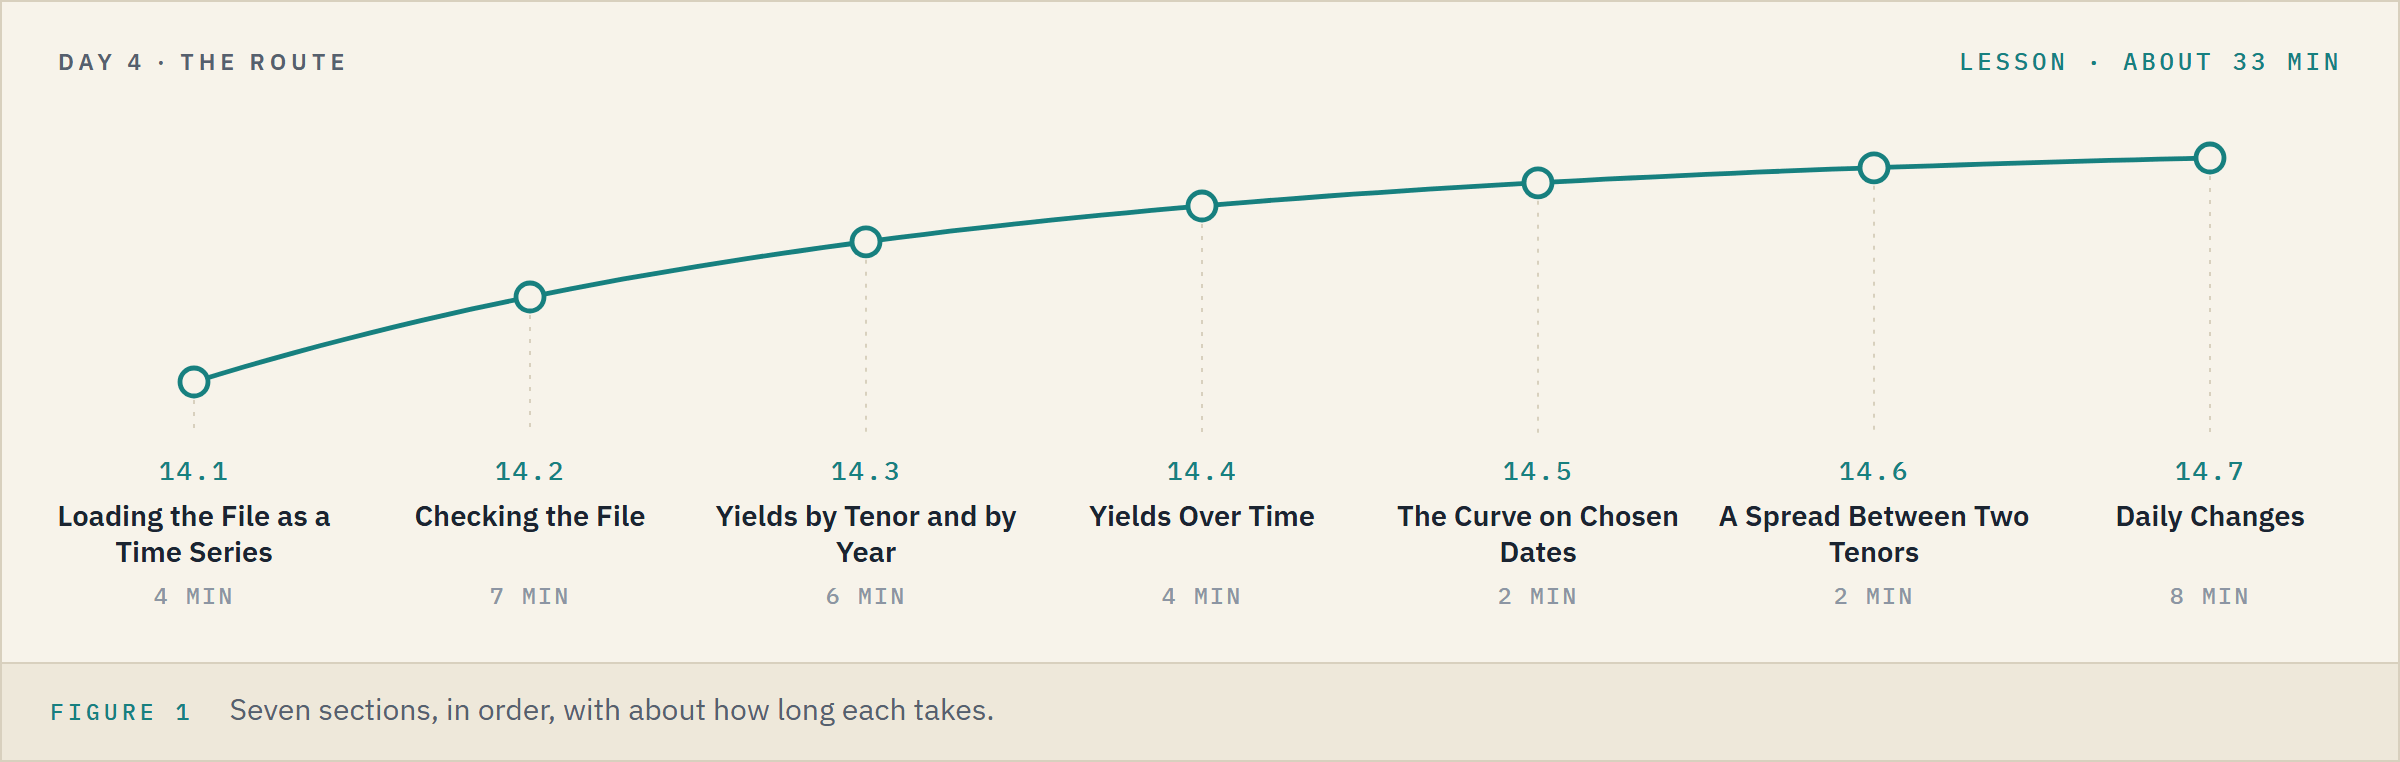

**Time.** About 33 minutes for the lesson, then about 21 for the seven exercises.

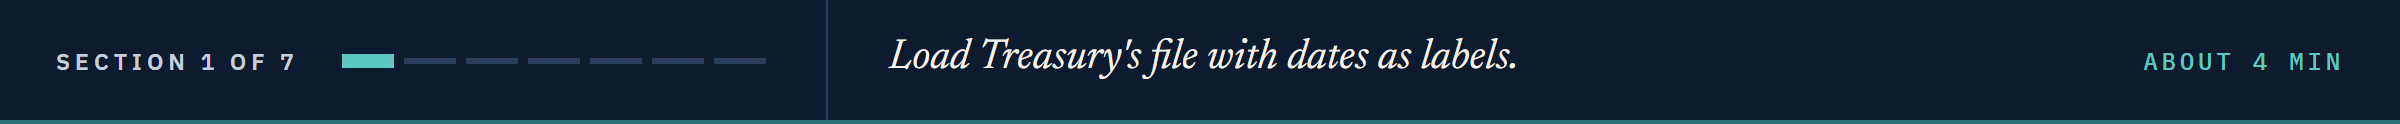

## 14.1 Loading the File as a Time Series

### Imports and a Plain Read

Q. Read the file as it stands. How large is it?

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house theme, as in Visualization: greens and greys, a dark median in a box
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
# the repo's data folder on your machine; in Colab, GitHub, as in pandas Part 1
if os.path.exists('../../../data/treasury_par_yields.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
raw = pd.read_csv(data_folder + 'treasury_par_yields.csv')
print(raw.shape)
raw.head(3)

(2940, 15)


,date,1 Mo,1.5 Month,2 Mo,3 Mo,4 Mo,6 Mo,1 Yr,2 Yr,3 Yr,5 Yr,7 Yr,10 Yr,20 Yr,30 Yr
0,2015-01-02,0.02,NaN,NaN,0.02,NaN,0.11,0.25,0.66,1.07,1.61,1.92,2.12,2.41,2.69
1,2015-01-05,0.02,NaN,NaN,0.03,NaN,0.10,0.26,0.68,1.06,1.57,1.85,2.04,2.32,2.60
2,2015-01-06,0.02,NaN,NaN,0.03,NaN,0.10,0.25,0.65,1.02,1.50,1.78,1.97,2.25,2.52


The file has 2,940 rows and 15 columns: `date` and fourteen tenors.
Three tenors start blank, `NaN`; `date` arrives as text, since a CSV holds no types, as Combining Part 2 showed.

### Ask for a Year

Q. Ask the plain table for the year of each row.

In [2]:
# raw's row labels are 0, 1, 2, ...: positions, not dates
raw.index.year

AttributeError: 'RangeIndex' object has no attribute 'year'

Read the last line, as in week 1's Day 3: a `RangeIndex`, the row numbers, has no year.

**The dates must become the row labels.**

### Dates as Row Labels

Q. Read the file again with the dates as the index. Are they in order, each one once?

In [3]:
# parse_dates= reads date as dates, as in Combining Part 2; index_col= makes it the row labels
yields = pd.read_csv(data_folder + 'treasury_par_yields.csv', parse_dates=['date'],
                     index_col='date')
# the fourteen tenor names, kept for when a column is added
tenors = list(yields.columns)
print(yields.shape, type(yields.index))
# is_monotonic_increasing: each date later than the one before
# is_unique, as in A First Look at the Data
print(yields.index.is_monotonic_increasing, yields.index.is_unique)
print(yields.index[0].date(), 'to', yields.index[-1].date())

(2940, 14) <class 'pandas.DatetimeIndex'>
True True
2015-01-02 to 2026-10-02


`date` became a `DatetimeIndex`, an index of dates: a table with dates as row labels is a **time series**.
In order and unique, so each row's change from the row above runs forward in time.

**Excel side by side.** Excel 365 converts the dates on opening, so `=ISNUMBER(A2)` is TRUE; column I holds the `2 Yr`, M the `10 Yr`.

### The File Draws Itself

Q. Draw four tenors over the whole span.

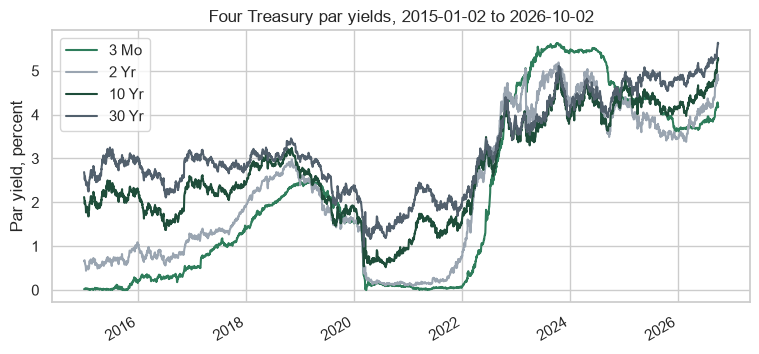

In [4]:
# four tenors from the short end to the long end
main = ['3 Mo', '2 Yr', '10 Yr', '30 Yr']
fig, ax = plt.subplots(figsize=(9, 4))
# one line per column; ax= puts them on our axes, and the date index becomes the x-axis
yields[main].plot(ax=ax)
ax.set_title('Four Treasury par yields, 2015-01-02 to 2026-10-02')
ax.set_xlabel('')
ax.set_ylabel('Par yield, percent')
plt.show()

One line of code drew 2,940 dates.
The `3 Mo` sits at the bottom for most of 2015 to 2021, then on top through 2023 and most of 2024.

**A date index: pick by date, group by year, draw against time. Now check the file.**

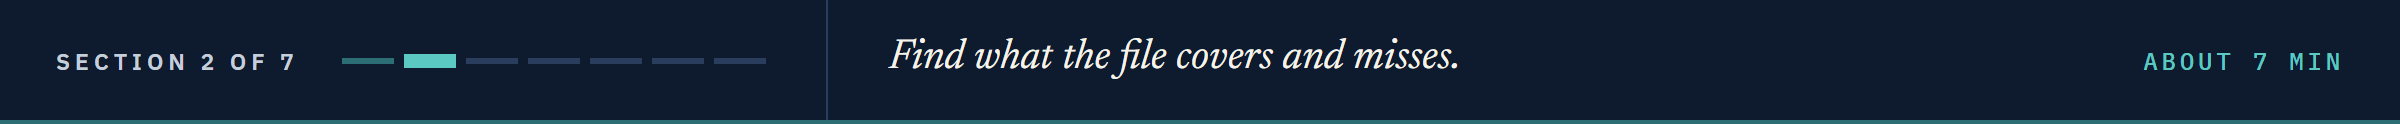

## 14.2 Checking the File

### One Date, One Cell

Q. What did four tenors read on 2020-03-09?

In [5]:
# a date label picks a row; a date and a column list pick cells
yields.loc['2020-03-09', main]

3 Mo     0.33
2 Yr     0.38
10 Yr    0.54
30 Yr    0.99
Name: 2020-03-09 00:00:00, dtype: float64

One row is one date's curve.

### Predict 1: A Year by Name

**Predict 1**

Q. 2020 had 366 days. What shape does `yields.loc['2020']` have?

A) (1, 14)
B) (366, 14)
C) about 250 rows, 14 columns

In [6]:
# a year alone picks every row of that year; a month works the same
print(yields.loc['2020'].shape)
print(yields.loc['2020-03'].shape)

(251, 14)
(22, 14)


C: 2020 has 251 rows, only the dates Treasury published.
Picking by part of a date is **partial string indexing**.

### Predict 2: Five Weekdays

**Predict 2**

Q. 2019-12-30 to 2020-01-03 is five weekdays, and a label slice keeps its end, as in pandas Part 1. How many rows come back?

A) 5
B) 4
C) 3

In [7]:
# a slice of dates and a list of columns
yields.loc['2019-12-30':'2020-01-03', ['2 Yr', '10 Yr']]

,2 Yr,10 Yr
date,,
2019-12-30,1.58,1.90
2019-12-31,1.58,1.92
2020-01-02,1.58,1.88
2020-01-03,1.53,1.80


B: New Year's Day, 2020-01-01, has no row.
It is absent, not blank: no cell says so.

### Rows per Year and per Weekday

Q. How many rows does each year have, and on which days of the week?

In [8]:
# .index.year: each row label's year (.month and .day work alike); size() counts rows per group
print(yields.groupby(yields.index.year).size().to_dict())
# .index.dayofweek: 0 is Monday, 4 Friday, 5 and 6 the weekend
print(yields.groupby(yields.index.dayofweek).size().to_dict())

{2015: 251, 2016: 250, 2017: 250, 2018: 249, 2019: 250, 2020: 251, 2021: 251, 2022: 249, 2023: 250, 2024: 250, 2025: 249, 2026: 190}
{0: 538, 1: 608, 2: 604, 3: 596, 4: 594}


A whole year has 249 to 251 rows; 2026, at 190, runs to 2 October.
Only weekdays appear, 538 Mondays against 608 Tuesdays: several holidays fall on a Monday.

### Weekdays With No Row

Q. Is 2024-07-04 in the file? Which weekdays have no row?

In [9]:
# in asks whether a label is in the index
print('2024-07-04' in yields.index, '2024-07-05' in yields.index)
# every weekday from the first date to the last: freq='B' is business days, Monday to Friday
weekdays = pd.date_range(yields.index[0], yields.index[-1], freq='B')
# difference(): the weekdays not in the file
no_row = weekdays.difference(yields.index)
print(len(weekdays), len(yields), len(no_row))
# the ones in 2024, as text with strftime, as in Combining Part 2
no_row[no_row.year == 2024].strftime('%Y-%m-%d').tolist()

False True
3066 2940 126


['2024-01-01',
 '2024-01-15',
 '2024-02-19',
 '2024-03-29',
 '2024-05-27',
 '2024-06-19',
 '2024-07-04',
 '2024-09-02',
 '2024-10-14',
 '2024-11-11',
 '2024-11-28',
 '2024-12-25']

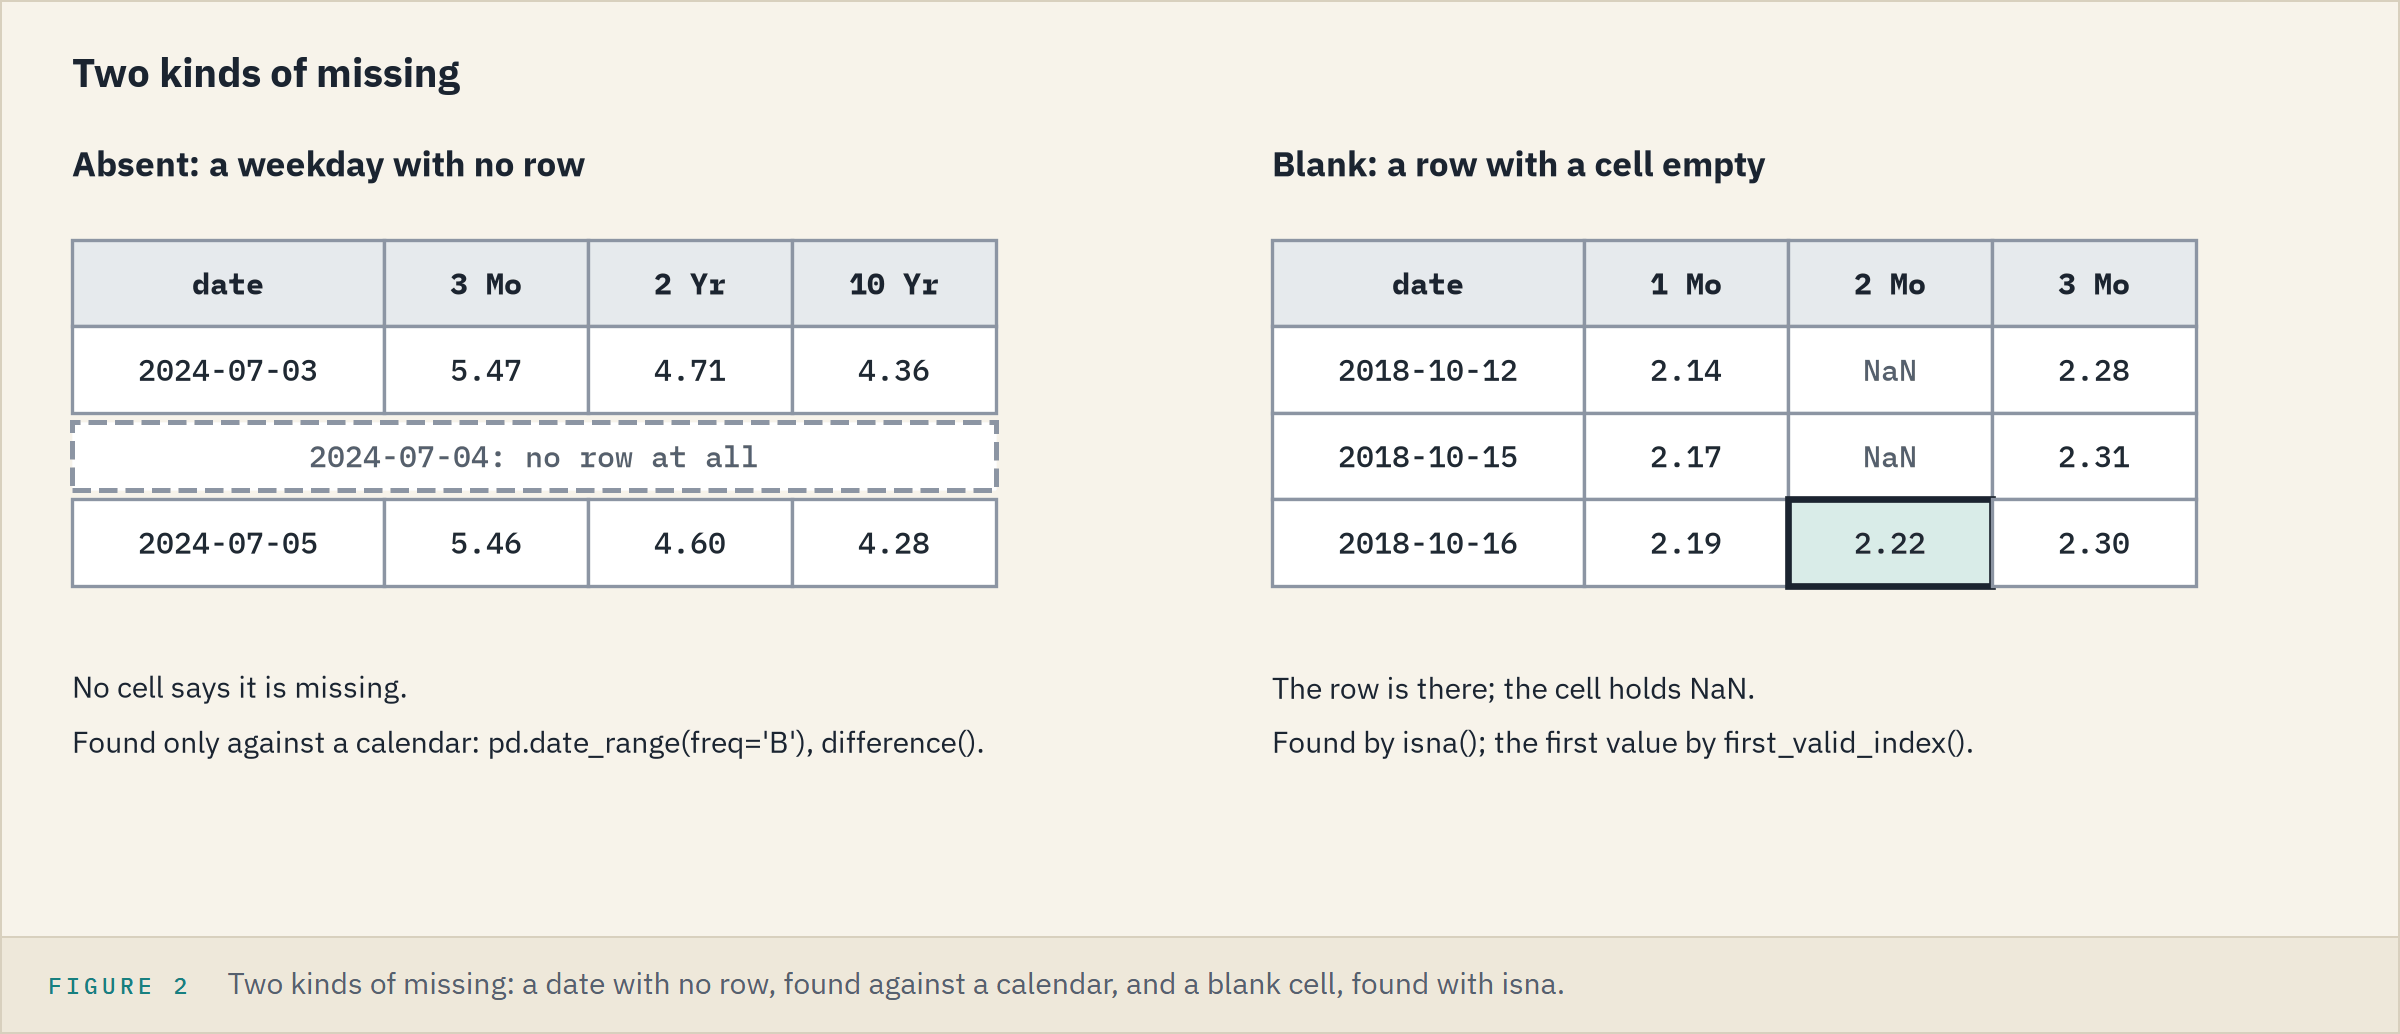

The span has 3,066 weekdays and the file 2,940 rows: 126 weekdays are absent, twelve of them in 2024.

### Blank Cells

Q. Where are the blanks, and when does each late tenor start?

In [10]:
# isna().sum(), as in Combining Part 1: blanks per column
blanks = yields.isna().sum()
print('Blank cells:', blanks.sum())
for tenor in ['2 Mo', '4 Mo', '1.5 Month']:
    # first_valid_index(): the first date with a value
    first = yields[tenor].first_valid_index()
    print(tenor, blanks[tenor], 'blank | first value', first.date(),
          '| blank after it:', yields.loc[first:, tenor].isna().sum())

Blank cells: 5432
2 Mo 949 blank | first value 2018-10-16 | blank after it: 0
4 Mo 1951 blank | first value 2022-10-19 | blank after it: 0
1.5 Month 2532 blank | first value 2025-02-18 | blank after it: 0


All 5,432 blanks fall before a late tenor's first date: nothing is scattered, so nothing needs filling.

> STORY: Why three columns start late. Treasury's bill timeline lists the first auction of 8-week bills in October 2018, of 17-week bills in October 2022, and of 6-week bills in February 2025. The `2 Mo`, `4 Mo`, and `1.5 Month` first have values in those months. Treasury builds the curve from the most recently auctioned bills, so a tenor has no par yield before its bill exists. Sources: [TreasuryDirect, bills timeline](https://www.treasurydirect.gov/research-center/timeline/bills/); [Treasury, yield curve methodology](https://home.treasury.gov/policy-issues/financing-the-government/interest-rate-statistics/treasury-yield-curve-methodology)

### An Average Over Part of a Year

Q. In 2018 the `2 Mo` averaged more than the `3 Mo`. Was it higher?

In [11]:
year_2018 = yields.loc['2018']
# the dates in 2018 on which the 2 Mo has a value
same_days = year_2018['2 Mo'].notna()
print('2 Mo:', year_2018['2 Mo'].count(), 'values, mean', round(year_2018['2 Mo'].mean(), 2))
print('3 Mo, whole year:', round(year_2018['3 Mo'].mean(), 2))
print('3 Mo, same days:', round(year_2018.loc[same_days, '3 Mo'].mean(), 2))

2 Mo: 51 values, mean 2.33
3 Mo, whole year: 1.97
3 Mo, same days: 2.38


Its 51 values are all from late 2018: on those days the `3 Mo` averaged more, 2.38.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">One date</td><td align="left"><code>yields.loc['2020-03-09', '10 Yr']</code></td><td align="left"><code>=XLOOKUP(DATE(2020,3,9), A2:A2941, M2:M2941)</code>, Excel 2021 on</td><td align="left">0.54</td></tr>
<tr><td align="left">Weekdays</td><td align="left"><code>pd.date_range(freq='B')</code></td><td align="left"><code>=NETWORKDAYS(A2, A2941)</code></td><td align="left">3,066</td></tr>
<tr><td align="left">Blanks</td><td align="left"><code>isna().sum()</code></td><td align="left"><code>=COUNTBLANK(D2:D2941)</code></td><td align="left">949</td></tr>
</table>
<br clear="left">

**126 days absent, 5,432 cells blank, nothing filled: put `count()` beside every average.**

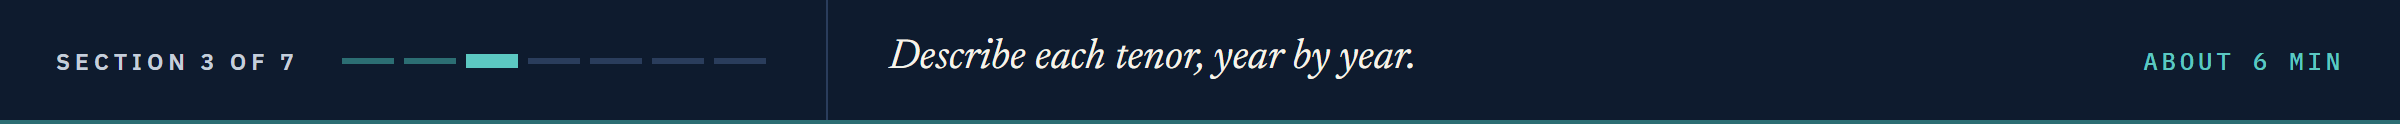

## 14.3 Yields by Tenor and by Year

### Every Tenor at Once

Q. Summarize all fourteen tenors.

In [12]:
# describe(), with .T to turn it so each tenor is a row, as NumPy Part 2's .T
yields.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2)

,count,mean,std,min,50%,max
1 Mo,2940.0,2.10,1.98,0.00,1.62,6.02
1.5 Month,408.0,4.02,0.29,3.65,4.00,4.53
2 Mo,1991.0,2.82,2.02,0.00,3.34,5.61
3 Mo,2940.0,2.16,1.96,0.00,1.69,5.63
4 Mo,989.0,4.66,0.66,3.58,4.52,5.64
6 Mo,2940.0,2.22,1.91,0.02,1.87,5.61
1 Yr,2940.0,2.24,1.79,0.04,1.94,5.49
2 Yr,2940.0,2.28,1.60,0.09,2.08,5.19
3 Yr,2940.0,2.34,1.48,0.10,2.15,5.03
5 Yr,2940.0,2.47,1.32,0.19,2.25,5.09


The `count` column shows the three late tenors.
The `10 Yr` ran 0.52 to 5.29, mean 2.76 above median 2.49.

Q. Draw each tenor's spread of values.

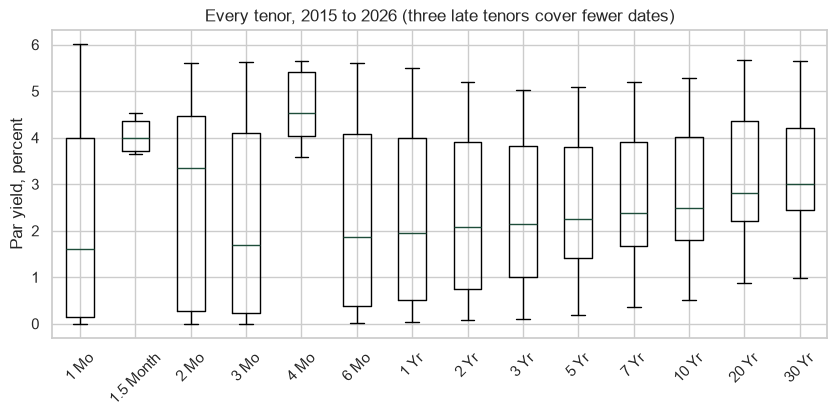

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
# one box per tenor, as in Visualization; dropna() because a box cannot hold a blank
ax.boxplot([yields[tenor].dropna() for tenor in tenors], tick_labels=tenors)
ax.tick_params(axis='x', rotation=45)
ax.set_title('Every tenor, 2015 to 2026 (three late tenors cover fewer dates)')
ax.set_ylabel('Par yield, percent')
plt.show()

Among the eleven full tenors, medians step up from 1.62 at the `1 Mo` to 3.00 at the `30 Yr`.
The three late boxes sit high: their dates start in 2018, 2022, and 2025.

### The 10 Yr Year by Year

Q. What were the `10 Yr`'s mean, low, high, and range in each year?

In [14]:
ten_year = yields.groupby(yields.index.year)['10 Yr'].agg(['mean', 'min', 'max']).round(2)
# .index.name labels the row labels
ten_year.index.name = 'year'
# round() first clears float error; astype(int) then drops the .0
ten_year['range_bp'] = ((ten_year['max'] - ten_year['min']) * 100).round().astype(int)
ten_year

,mean,min,max,range_bp
year,,,,
2015,2.14,1.68,2.50,82
2016,1.84,1.37,2.60,123
2017,2.33,2.05,2.62,57
2018,2.91,2.44,3.24,80
2019,2.14,1.47,2.79,132
2020,0.89,0.52,1.88,136
2021,1.45,0.93,1.74,81
2022,2.95,1.63,4.25,262
2023,3.96,3.30,4.98,168


The mean was lowest in 2020, 0.89, and highest among whole years in 2025, 4.29; the range was widest in 2022, 262 bp, and narrowest in 2017, 57.

### Wide and Long

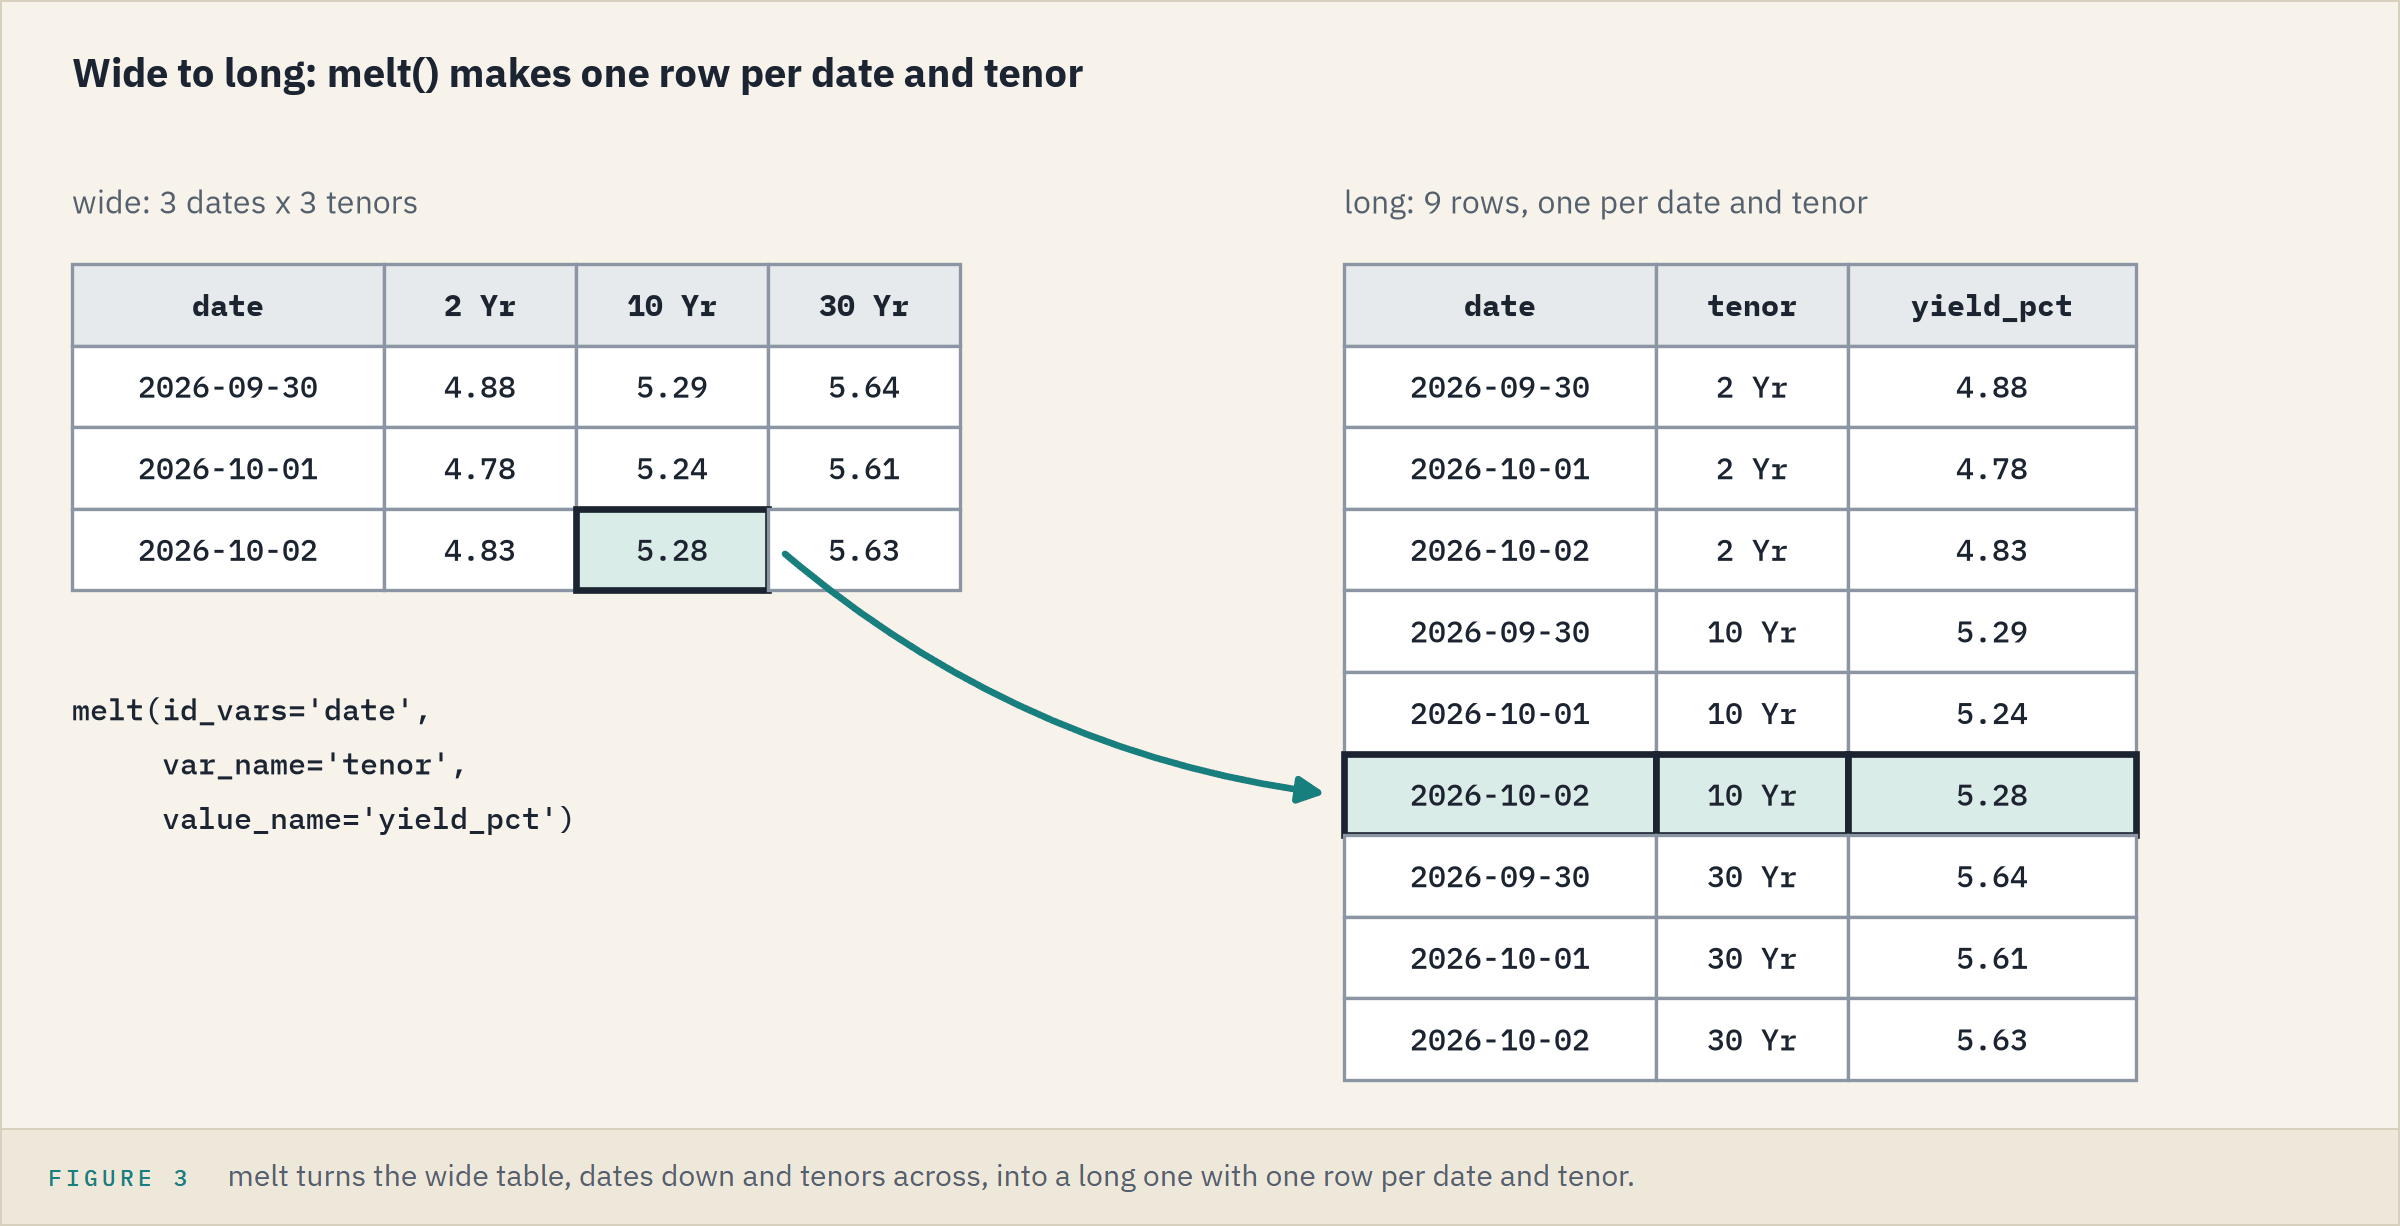

Seaborn's panels want **long** data, one row per date and tenor: `melt()` makes it.

### Predict 3: Melt

**Predict 3**

Q. `yields` has 2,940 rows, 14 tenors, and 5,432 blank cells. What shape does the long table have?

A) (2940, 3)
B) (35728, 3)
C) (41160, 3)

In [15]:
# reset_index() puts the dates back as a column; melt() makes one row per date and tenor
# id_vars= keeps date as it is; var_name= and value_name= name the two new columns
long = yields.reset_index().melt(id_vars='date', var_name='tenor', value_name='yield_pct')
print(long.shape)
long.head(3)

(41160, 3)


,date,tenor,yield_pct
0,2015-01-02,1 Mo,0.02
1,2015-01-05,1 Mo,0.02
2,2015-01-06,1 Mo,0.02


C: 2,940 times 14 rows, because `melt()` keeps the blank cells as `NaN` rows.

### Year by Tenor

Q. What was each tenor's mean in each year?

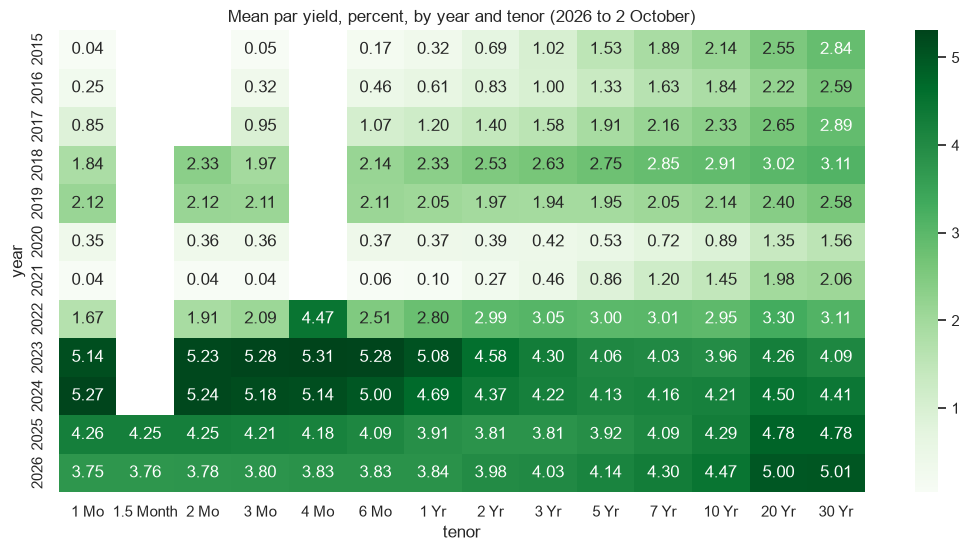

In [16]:
# a year column, with .dt.year as in Combining Part 2
long['year'] = long['date'].dt.year
by_year = long.pivot_table(index='year', columns='tenor', values='yield_pct', aggfunc='mean')
# pivot_table sorts tenors as text: [tenors] puts them back in curve order
by_year = by_year[tenors].round(2)
fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(by_year, annot=True, fmt='.2f', cmap='Greens', ax=ax)
ax.grid(False)  # no grid lines across the blank cells, as in Visualization
ax.set_title('Mean par yield, percent, by year and tenor (2026 to 2 October)')
plt.show()

Each row is a year's average curve: pale in 2020 and 2021, dark in 2023 and 2024.
The `3 Mo` ran from 0.04 in 2021 to 5.28 in 2023; the `4 Mo`'s 2022, 4.47, covers only its dates from 2022-10-19.

### A Panel per Tenor

Q. Draw every tenor over time, one panel each.

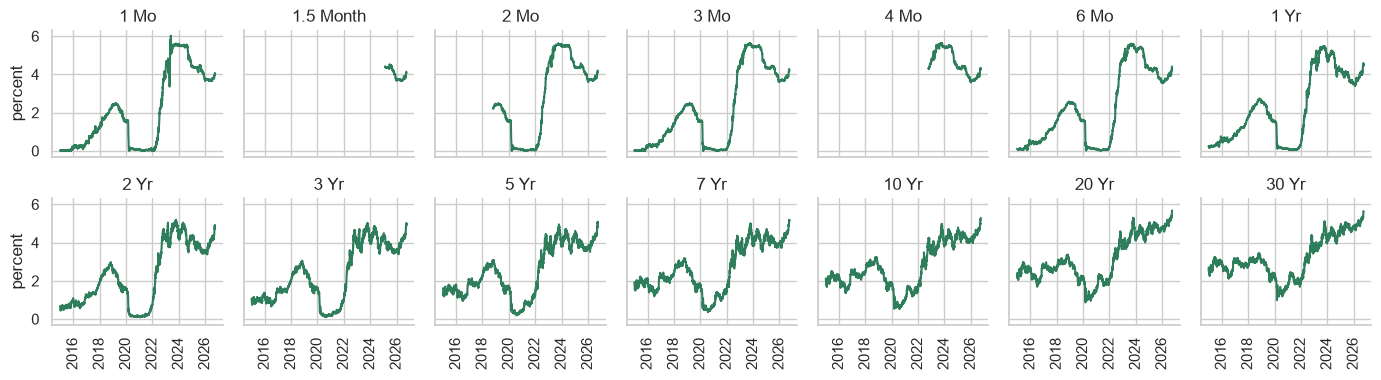

In [17]:
# relplot, as in the EDA notebook; kind='line' joins the points in date order
grid = sns.relplot(data=long, x='date', y='yield_pct', col='tenor', kind='line',
                   col_wrap=7, height=2)
grid.set_titles('{col_name}')
grid.set_axis_labels('', 'percent')
grid.tick_params(axis='x', rotation=90)
plt.show()

One shared scale: the three late tenors start where the story said.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">A year's mean</td><td align="left"><code>groupby(...).agg(...)</code></td><td align="left"><code>=AVERAGEIFS(M:M, P:P, 2020)</code> with <code>=YEAR(A2)</code> in P; <code>MAXIFS</code>, <code>MINIFS</code> from Excel 2019</td></tr>
<tr><td align="left">Wide to long</td><td align="left"><code>melt()</code></td><td align="left">Power Query, Unpivot Other Columns, which leaves out null cells</td></tr>
<tr><td align="left">Shade a table</td><td align="left"><code>sns.heatmap()</code></td><td align="left">Conditional Formatting, Color Scales</td></tr>
</table>
<br clear="left">

**Averages by year say where each tenor sat. Next: when.**

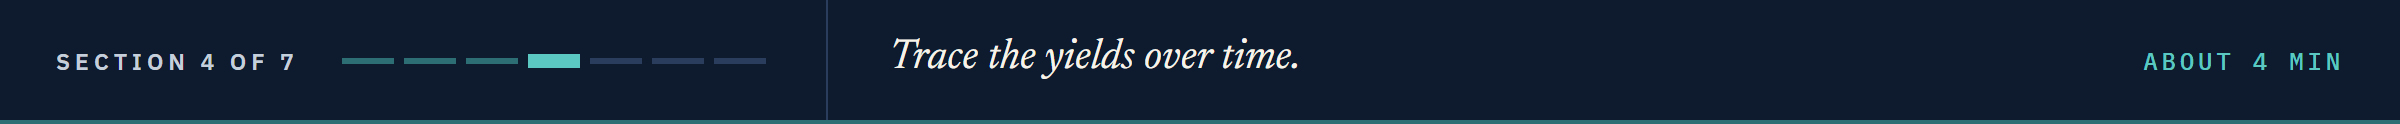

## 14.4 Yields Over Time

### Yearly Averages as Points

Q. Draw four tenors' yearly means as points.

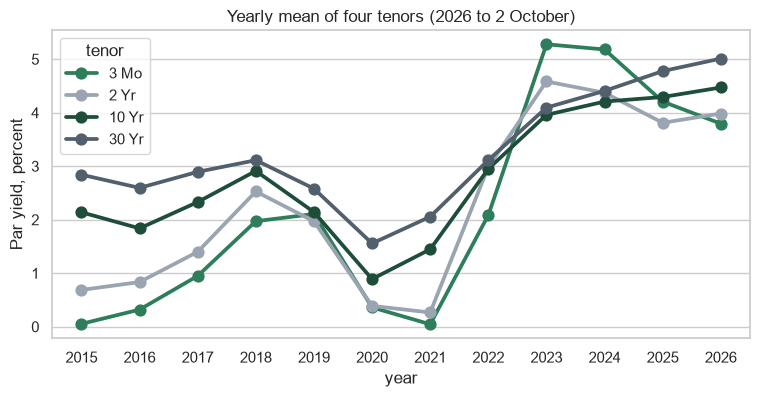

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
# pointplot: the mean of each x as a point, joined by a line; errorbar=None leaves out the bars
sns.pointplot(data=long[long['tenor'].isin(main)], x='year', y='yield_pct', hue='tenor',
              errorbar=None, ax=ax)
ax.set_title('Yearly mean of four tenors (2026 to 2 October)')
ax.set_ylabel('Par yield, percent')
plt.show()

In 2023 the short end is on top: the `3 Mo` at 5.28, the `10 Yr` lowest at 3.96.

### Which Tenor Was Highest

Q. On each date, which of the four was highest?

In [19]:
# idxmax(axis=1) works along each row and returns the column name
top = yields[main].idxmax(axis=1)
print(top.value_counts())
top.loc['2023'].value_counts()

30 Yr    2335
3 Mo      508
2 Yr       95
10 Yr       2
Name: count, dtype: int64


3 Mo    250
Name: count, dtype: int64

The `30 Yr` was highest on 2,335 dates and the `3 Mo` on 508, all 250 of 2023 among them.
On a tie, `idxmax()` names the first column.

### Highs, Lows, and Their Dates

Q. When was each tenor at its high and its low?

In [20]:
for tenor in main:
    # idxmin() is idxmax()'s twin: the first date of the low
    print(tenor, '| high', yields[tenor].max(), yields[tenor].idxmax().date(),
          '| low', yields[tenor].min(), yields[tenor].idxmin().date())
print('3 Mo at 0.00:', (yields['3 Mo'] == 0).sum(), 'dates')

3 Mo | high 5.63 2023-10-06 | low 0.0 2015-09-18
2 Yr | high 5.19 2023-10-17 | low 0.09 2021-02-05
10 Yr | high 5.29 2026-09-30 | low 0.52 2020-08-04
30 Yr | high 5.64 2026-09-30 | low 0.99 2020-03-09
3 Mo at 0.00: 13 dates


The `10 Yr` peaked at 5.29 on 2026-09-30.
The `3 Mo` sat at 0.00 on 13 dates; the date printed is the first.

### Predict 4: Month End

**Predict 4**

Q. `resample('ME')` groups the rows by calendar month; `.last()` keeps each month's last value. January 2015 to October 2026: what shape comes back?

A) (12, 14)
B) (141, 14)
C) (142, 14)

In [21]:
# 'ME' is month end ('M' before pandas 2.2)
month_end = yields[tenors].resample('ME').last()
print(month_end.shape)
print(month_end[['2 Yr', '10 Yr']].tail(2))
# the first label, January's last 10 Yr, and January's mean
print('2015-01-31' in yields.index, month_end['10 Yr'].iloc[0],
      round(yields.loc['2015-01', '10 Yr'].mean(), 2))

(142, 14)
            2 Yr  10 Yr
date                   
2026-09-30  4.88   5.29
2026-10-31  4.83   5.28
False 1.68 1.88


C: there is one row per month, 142, each labelled by its month end and holding the last value found.
2026-10-31 holds 2026-10-02's figures, a part month; 2015-01-31's 1.68 is January's last `10 Yr`, not its mean, 1.88.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Date of the high</td><td align="left"><code>idxmax()</code></td><td align="left"><code>=XLOOKUP(MAX(M2:M2941), M2:M2941, A2:A2941)</code></td><td align="left">2026-09-30</td></tr>
<tr><td align="left">Month-end value</td><td align="left"><code>resample('ME').last()</code></td><td align="left"><code>=XLOOKUP(EOMONTH(DATE(2015,1,1),0), A2:A2941, M2:M2941, , -1)</code></td><td align="left">1.68</td></tr>
</table>
<br clear="left">

**Say which monthly figure it is, and flag the part month.**

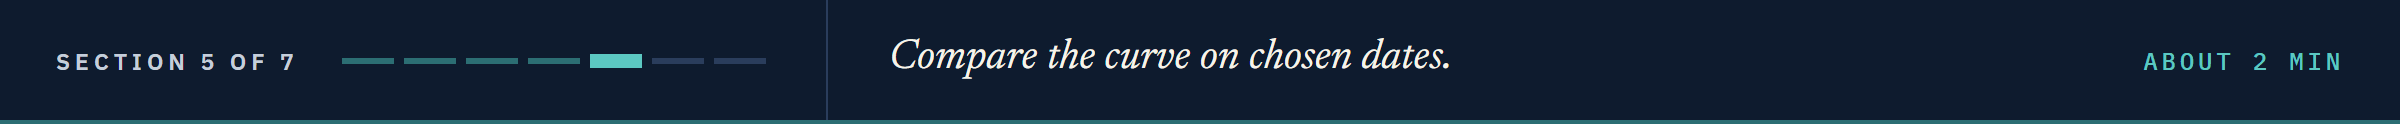

## 14.5 The Curve on Chosen Dates

### Tenors in Years, Dates by Rule

Q. With each tenor given its length in years, what did five tenors read on the first date, the last, and the date the `2 Yr` sat furthest above the `10 Yr`?

In [22]:
# one tenor name to its length in years, a dictionary as in week 1's Day 1
tenor_years = {'1 Mo': 1 / 12, '1.5 Month': 1.5 / 12, '2 Mo': 2 / 12, '3 Mo': 3 / 12,
               '4 Mo': 4 / 12, '6 Mo': 0.5, '1 Yr': 1, '2 Yr': 2, '3 Yr': 3, '5 Yr': 5,
               '7 Yr': 7, '10 Yr': 10, '20 Yr': 20, '30 Yr': 30}
# dates chosen by rule, not by eye: idxmin() gives the date of the lowest 10 Yr less 2 Yr
furthest = (yields['10 Yr'] - yields['2 Yr']).idxmin()
dates = [yields.index[0], furthest, yields.index[-1]]
yields.loc[dates, ['1 Mo', '2 Yr', '10 Yr', '20 Yr', '30 Yr']]

,1 Mo,2 Yr,10 Yr,20 Yr,30 Yr
date,,,,,
2015-01-02,0.02,0.66,2.12,2.41,2.69
2023-07-03,5.27,4.94,3.86,4.08,3.87
2026-10-02,4.04,4.83,5.28,5.67,5.63


On 2023-07-03 the `2 Yr`, 4.94, sat 108 bp above the `10 Yr`, 3.86.

### Three Curves

Q. Draw the curve on those three dates, each tenor at its length in years.

2015-01-02 11 points
2023-07-03 13 points
2026-10-02 14 points


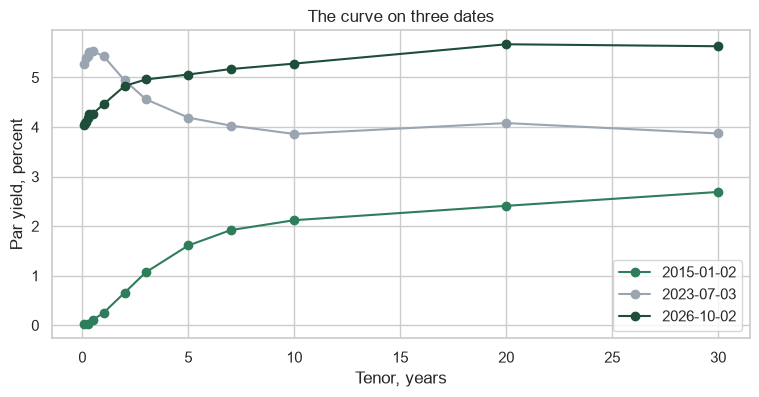

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
for day in dates:
    curve = yields.loc[day, tenors].dropna()
    ax.plot([tenor_years[tenor] for tenor in curve.index], curve, marker='o', label=day.date())
    print(day.date(), len(curve), 'points')
ax.set_title('The curve on three dates')
ax.set_xlabel('Tenor, years')
ax.set_ylabel('Par yield, percent')
ax.legend()
plt.show()

The curves have 11, 13, and 14 points: each date has only the tenors that existed then.
On 2023-07-03 the curve sat highest at the short end; on the last date it rose from 4.04 at the `1 Mo`, with the `20 Yr`, 5.67, above the `30 Yr`, 5.63.

**Excel side by side.** Scatter with Straight Lines places each point by its x in years, as `ax.plot()` does; a Line chart spaces text labels evenly.

**2023-07-03, chosen by rule. Next, the 10 Yr less 2 Yr on every date.**

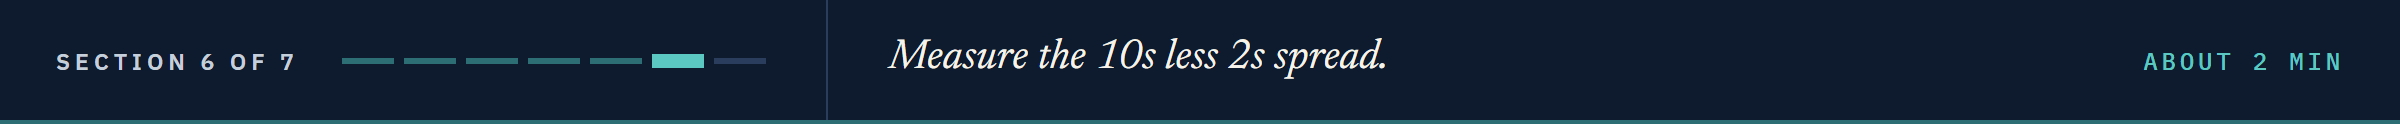

## 14.6 A Spread Between Two Tenors

### 10 Yr Less 2 Yr

Q. Add the spread in whole basis points. What does it look like?

In [24]:
# the unit in the name; tenors still lists the fourteen yields
yields['spread_bp'] = ((yields['10 Yr'] - yields['2 Yr']) * 100).round()
print(yields['spread_bp'].iloc[0], yields['spread_bp'].iloc[-1])
print('mean', round(yields['spread_bp'].mean(), 1), '| median', yields['spread_bp'].median())
print('low', yields['spread_bp'].min(), yields['spread_bp'].idxmin().date())
print('high', yields['spread_bp'].max(), 'on',
      (yields['spread_bp'] == yields['spread_bp'].max()).sum(), 'dates')

146.0 45.0
mean 48.1 | median 50.0
low -108.0 2023-07-03
high 177.0 on 2 dates


The spread was 146 bp on the first date and 45 on the last; its low, -108, fell on 2023-07-03 again.

### The Spread Over Time

Q. Draw the spread, with zero marked.

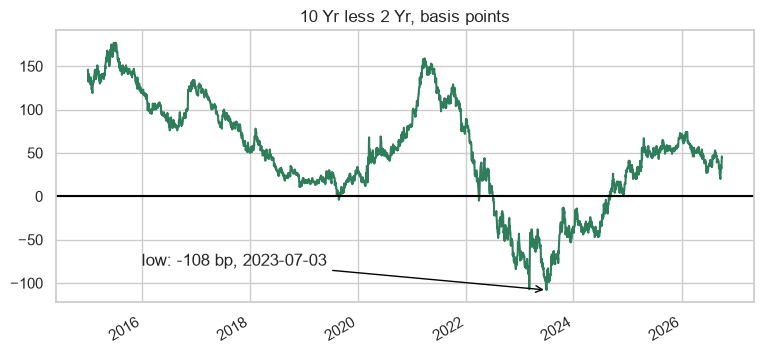

In [25]:
fig, ax = plt.subplots(figsize=(9, 4))
yields['spread_bp'].plot(ax=ax)
ax.axhline(0, color='black')
low = yields['spread_bp'].idxmin()
ax.annotate('low: -108 bp, 2023-07-03', xy=(low, -108), xytext=(pd.Timestamp('2016-01-01'), -80),
            arrowprops={'arrowstyle': '->', 'color': 'black'})
ax.set_title('10 Yr less 2 Yr, basis points')
ax.set_xlabel('')
plt.show()

### Days Below Zero

Q. How many days was it below zero, and in which years?

In [26]:
below = yields['spread_bp'] < 0
# the mean of True and False is the share that is True
print(below.sum(), 'days,', round(below.mean() * 100, 1), 'percent; at zero:',
      (yields['spread_bp'] == 0).sum())
print(yields.index[below][0].date(), 'to', yields.index[below][-1].date())
by_year_below = below.groupby(yields.index.year).sum()
by_year_below[by_year_below > 0]

544 days, 18.5 percent; at zero: 7
2019-08-27 to 2024-09-05


date
2019      3
2022    125
2023    250
2024    166
Name: spread_bp, dtype: int64

It was below zero on 544 days, 18.5 percent of the file, from 2019-08-27 to 2024-09-05; `< 0` leaves out the 7 at exactly zero.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Days below zero</td><td align="left"><code>(yields['spread_bp'] &lt; 0).sum()</code></td><td align="left"><code>=COUNTIF(Q2:Q2941, "&lt;0")</code>, with <code>=(M2-I2)*100</code> filled down Q</td><td align="left">544</td></tr>
<tr><td align="left">In one year</td><td align="left"><code>groupby(...).sum()</code></td><td align="left"><code>=COUNTIFS(Q2:Q2941, "&lt;0", P2:P2941, 2023)</code></td><td align="left">250</td></tr>
</table>
<br clear="left">

**544 days below zero, every day of 2023. Last: how far yields move in a day.**

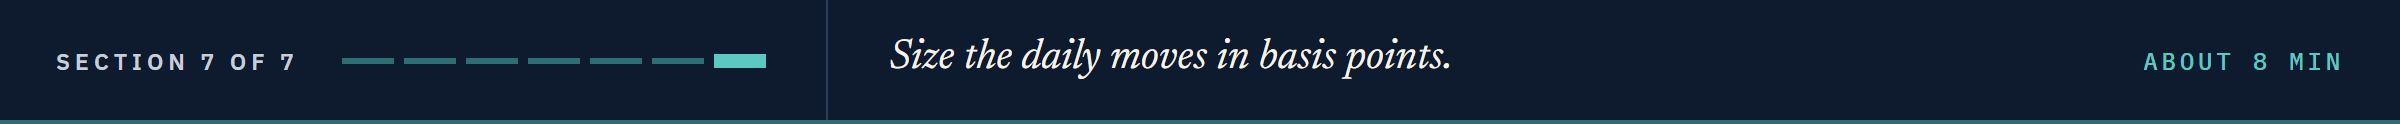

## 14.7 Daily Changes

### Predict 5: The First Change

**Predict 5**

Q. `diff()` takes each row less the row before. The file has 2,940 rows. How many `10 Yr` changes come back?

A) 2940
B) 2939
C) 2938

In [27]:
# each row less the row before, times 100 for basis points, rounded to whole bp
changes = (yields[tenors].diff() * 100).round()
print(changes['10 Yr'].count())
changes['10 Yr'].head(3)

2939


date
2015-01-02    NaN
2015-01-05   -8.0
2015-01-06   -7.0
Name: 10 Yr, dtype: float64

B: the first row has no row before it, so its change is `NaN`.
`diff()` is row to row: across an absent day it spans two.

### Four Tenors, Day to Day

Q. How large are the daily changes?

In [28]:
changes[main].describe().round(2)

,3 Mo,2 Yr,10 Yr,30 Yr
count,2939.00,2939.00,2939.00,2939.00
mean,0.14,0.14,0.11,0.10
std,2.95,5.19,5.30,5.05
min,-23.00,-57.00,-30.00,-31.00
25%,-1.00,-2.00,-3.00,-3.00
50%,0.00,0.00,0.00,0.00
75%,1.00,3.00,3.00,3.00
max,34.00,34.00,29.00,29.00


A typical `10 Yr` day is 5.30 bp, the middle half -3 to 3; the `3 Mo` moves least, 2.95.

### The 10 Yr's Daily Change

Q. Draw the `10 Yr`'s changes, one bar per basis point.

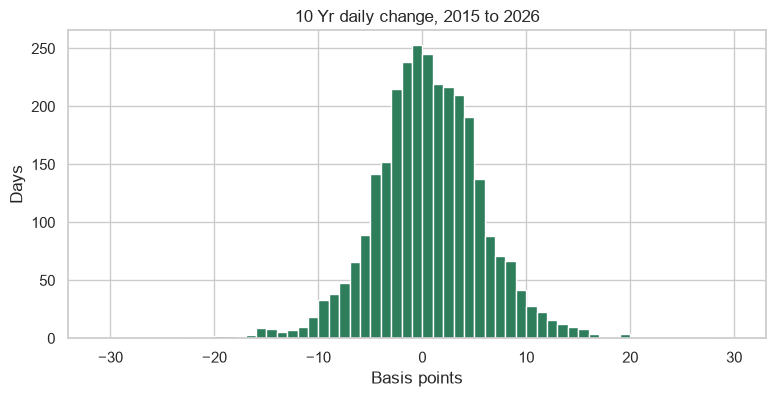

up 1351 | down 1343 | flat 245 | within 5 bp 2219


In [29]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(changes['10 Yr'].dropna(), bins=range(-31, 31))
ax.set_title('10 Yr daily change, 2015 to 2026')
ax.set_xlabel('Basis points')
ax.set_ylabel('Days')
plt.show()
ten = changes['10 Yr']
# abs() drops the sign, as in the EDA notebook
print('up', (ten > 0).sum(), '| down', (ten < 0).sum(), '| flat', (ten == 0).sum(),
      '| within 5 bp', (ten.abs() <= 5).sum())

On 2,219 of 2,939 days the move was 5 bp or less; the single days at 29 and -30 are too thin to see.

### The Largest Moves

Q. Which were the largest rises and falls, and when?

In [30]:
print(changes['10 Yr'].nlargest(3))
print(changes['10 Yr'].nsmallest(3))
# the days that moved 10 bp or more, either way, by year
big = changes['10 Yr'].abs() >= 10
big.groupby(yields.index.year).sum().to_dict()

date
2020-03-17    29.0
2022-06-13    28.0
2020-03-10    22.0
Name: 10 Yr, dtype: float64
date
2022-11-10   -30.0
2022-09-28   -25.0
2023-03-10   -23.0
Name: 10 Yr, dtype: float64


{2015: 20,
 2016: 9,
 2017: 2,
 2018: 2,
 2019: 11,
 2020: 15,
 2021: 7,
 2022: 48,
 2023: 55,
 2024: 22,
 2025: 14,
 2026: 6}

The largest rise, 29 bp on 2020-03-17; the largest fall, -30 on 2022-11-10.
Moves of 10 bp or more came 55 times in 2023 and 48 in 2022, against 2 each in 2017 and 2018.
The file says when, never why.

### Do the Tenors Move Together?

Q. How correlated are the tenors, as levels and as daily changes?

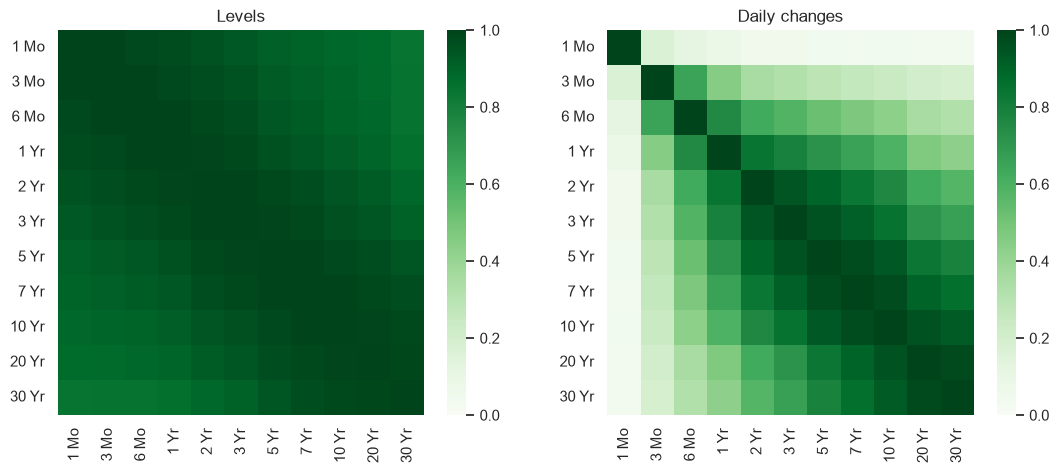

In [31]:
# the eleven tenors with no blank
complete = [tenor for tenor in tenors if yields[tenor].notna().all()]
# plt.subplots(1, 2), as in the EDA notebook: axes holds both, left first
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, table, name in zip(axes, [yields[complete], changes[complete]],
                           ['Levels', 'Daily changes']):
    sns.heatmap(table.corr(), vmin=0, vmax=1, cmap='Greens', ax=ax)
    ax.set_title(name)
    ax.tick_params(axis='y', rotation=0)
plt.show()

In [32]:
# three pairs: the correlation as levels, then as daily changes
for a, b in [('1 Mo', '30 Yr'), ('2 Yr', '10 Yr'), ('7 Yr', '10 Yr')]:
    print(a, b, round(yields[a].corr(yields[b]), 2), round(changes[a].corr(changes[b]), 2))

1 Mo 30 Yr 0.85 0.03
2 Yr 10 Yr 0.95 0.76
7 Yr 10 Yr 1.0 0.98


As levels, even the `1 Mo` and `30 Yr` correlate at 0.85: every tenor rose and fell with the years.
As daily changes those two barely do, 0.03; neighbours still do, 0.98.

### Predict 6: A 20-Row Window

**Predict 6**

Q. `rolling(20).mean()` averages the 20 rows ending on each date. How many `NaN` does `yields['10 Yr'].rolling(20).mean()` leave? Write down a number.

In [33]:
average_20 = yields['10 Yr'].rolling(20).mean()
print('missing:', average_20.isna().sum())
print(round(average_20.dropna().iloc[0], 2), average_20.first_valid_index().date())

missing: 19
1.88 2015-01-30


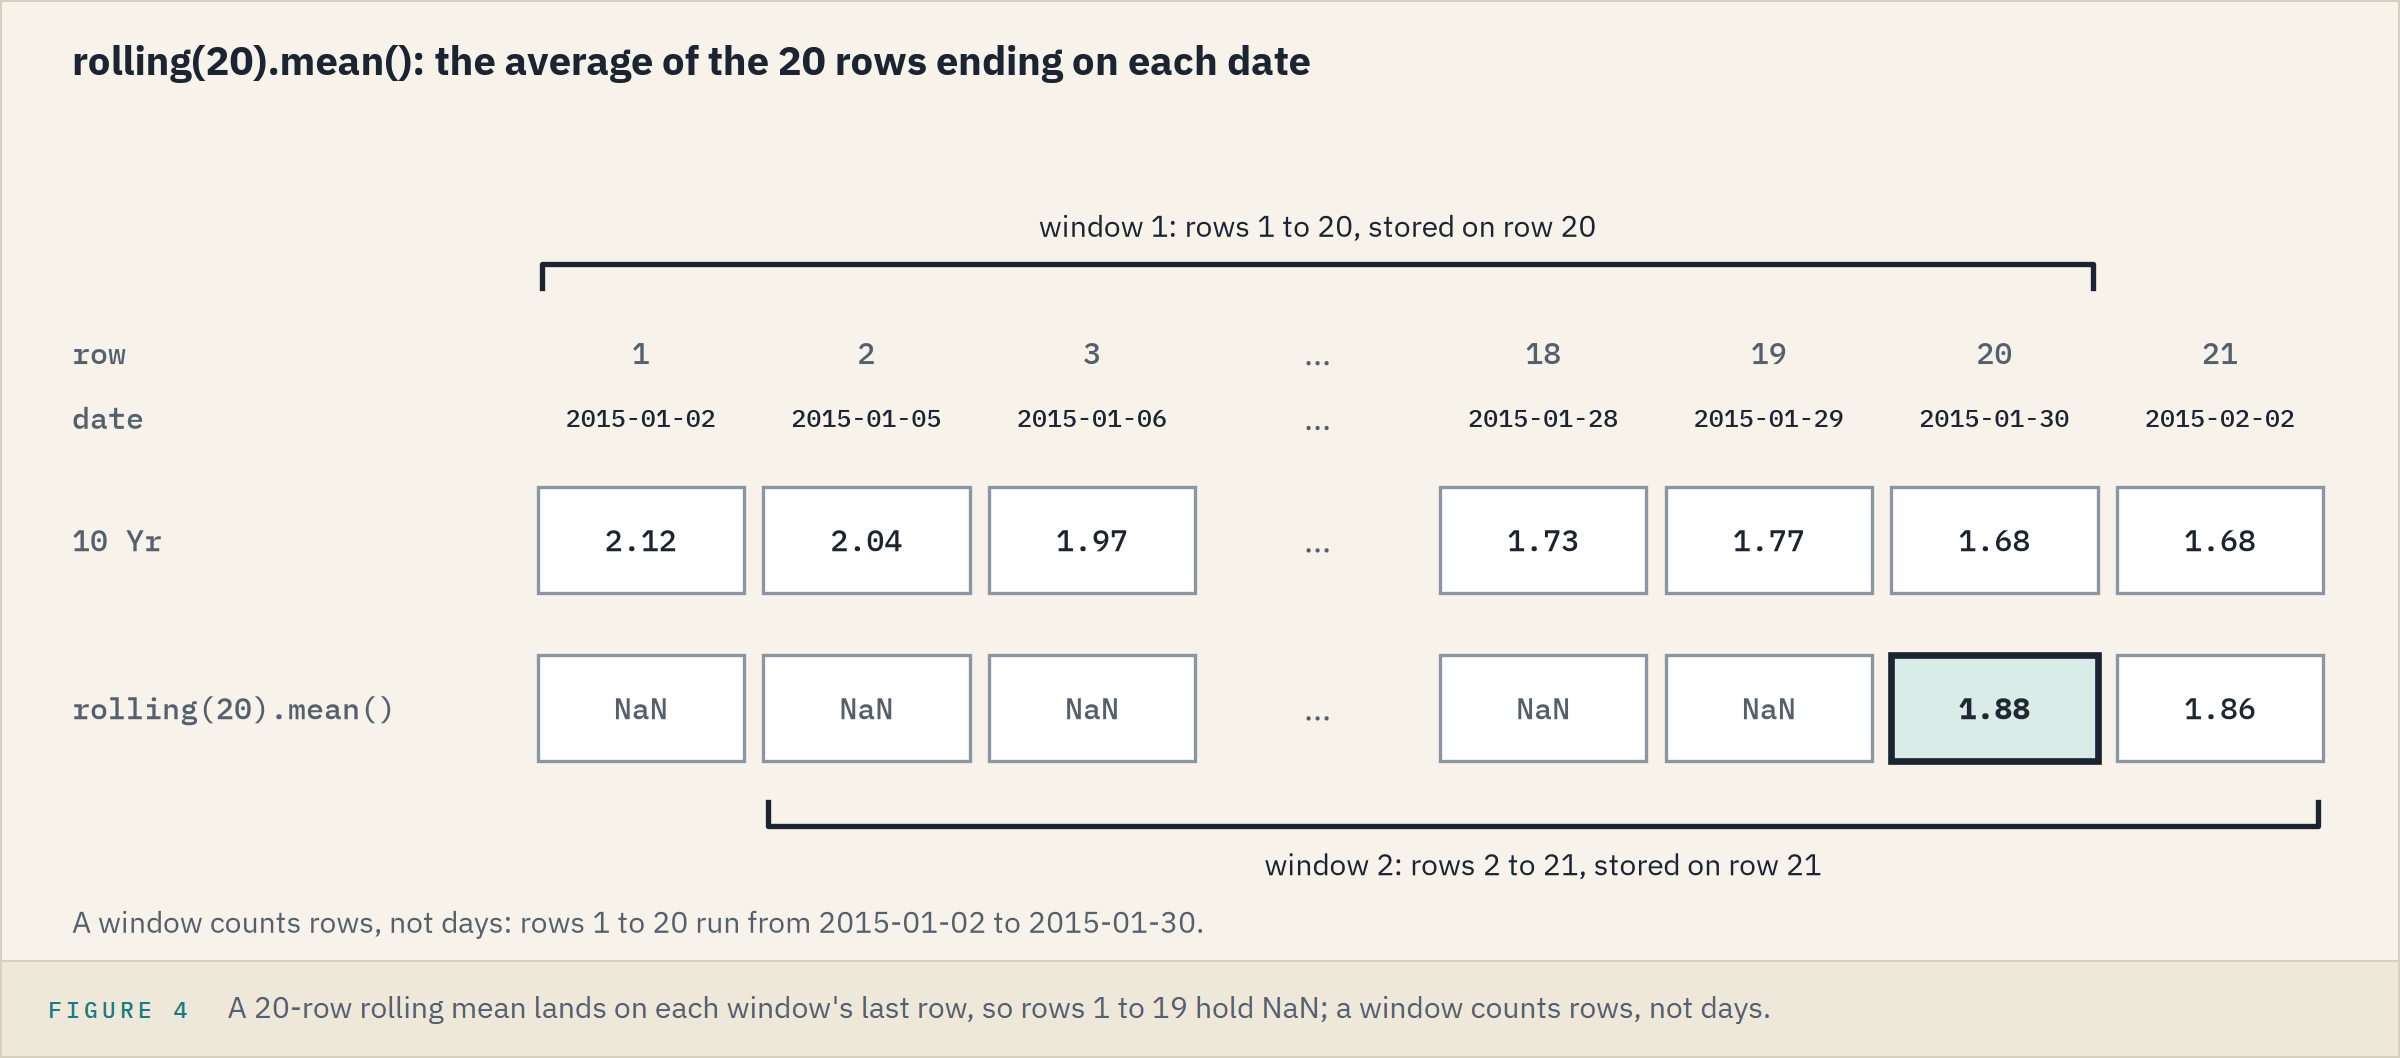

19: the first window ends on row 20, 2015-01-30, at 1.88.

### How Much a Day, Date by Date

Q. Over each 20-row window, how large is the typical `10 Yr` change?

In [34]:
moving_std = changes['10 Yr'].rolling(20).std()
print('missing:', moving_std.isna().sum(), '| whole span:', round(changes['10 Yr'].std(), 2))
print('low', round(moving_std.min(), 2), moving_std.idxmin().date(),
      '| high', round(moving_std.max(), 2), moving_std.idxmax().date(),
      '| last', round(moving_std.iloc[-1], 2))

missing: 20 | whole span: 5.3
low 1.93 2021-01-05 | high 14.51 2020-03-26 | last 5.34


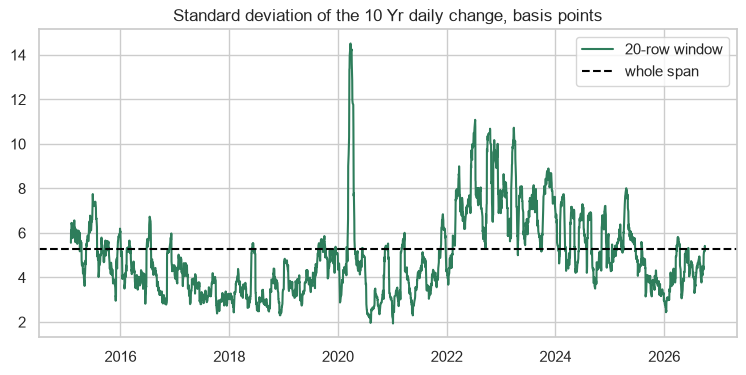

In [35]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(moving_std, label='20-row window')
ax.axhline(changes['10 Yr'].std(), color='black', linestyle='--', label='whole span')
ax.set_title('Standard deviation of the 10 Yr daily change, basis points')
ax.legend()
plt.show()

It leaves 20 missing, one more, because the first change is itself `NaN`.
It ran from 1.93 to 14.51 bp and reads 5.34 on the last date, against 5.30 for the span: a description, not a forecast.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th></tr>
<tr><td align="left">Daily change</td><td align="left"><code>diff() * 100</code></td><td align="left"><code>=(M3-M2)*100</code> in R3, filled down</td></tr>
<tr><td align="left">Largest moves</td><td align="left"><code>nlargest()</code>, <code>nsmallest()</code></td><td align="left"><code>=LARGE(R3:R2941, 1)</code>, <code>=SMALL(R3:R2941, 1)</code></td></tr>
<tr><td align="left">20-row average</td><td align="left"><code>rolling(20).mean()</code></td><td align="left"><code>=AVERAGE(M2:M21)</code> filled down, or a Moving Average trendline, period 20</td></tr>
</table>
<br clear="left">

**5.30 bp a day over the span, 5.34 on the last date: the sheet's last line.**

## Summary

The checks behind every answer:

<table align="left">
<tr><th align="left">Check</th><th align="left">Result</th></tr>
<tr><td align="left">Span</td><td align="left">2015-01-02 to 2026-10-02: 2,940 dates, 14 tenors, in order, none repeated</td></tr>
<tr><td align="left">Absent</td><td align="left">126 of 3,066 weekdays; 249 to 251 rows a whole year, 2026 a part year</td></tr>
<tr><td align="left">Blank</td><td align="left">5,432 cells, three tenors before their first date</td></tr>
<tr><td align="left">Changed</td><td align="left">nothing; <code>spread_bp</code> added</td></tr>
</table>
<br clear="left">

## You Can Now

By the end of this notebook, you can:

* Read a file as a time series with `parse_dates=` and `index_col=`.
* Pick dates with `.loc` and group by `.index.year`.
* Find absent weekdays with `pd.date_range()` and `difference()`.
* Reshape with `melt()` and draw `relplot(kind='line')` and `pointplot()`.
* Take month ends with `resample('ME').last()`.
* Work out changes with `diff()` and windows with `rolling()`.
* Describe a series with dates, numbers, and units, never why.

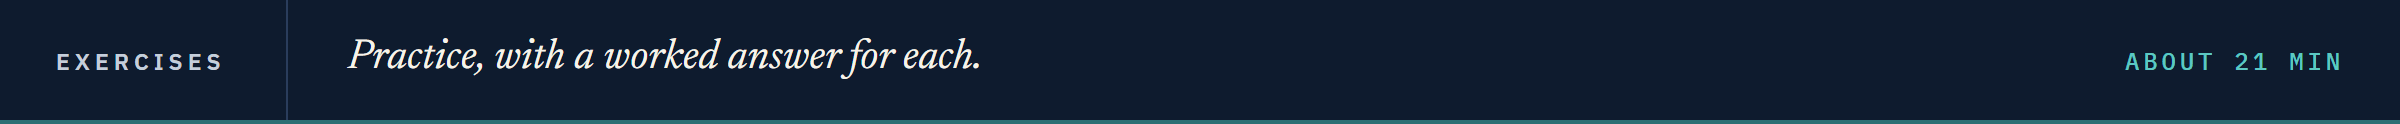

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your code, then run the check cell under it.
First run the next two cells: `check` marks answers; the loader reads a fresh `yields`.

In [36]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [37]:
# a fresh yields, the dates as the row labels
yields = pd.read_csv(data_folder + 'treasury_par_yields.csv', parse_dates=['date'],
                     index_col='date')
print(yields.shape)

(2940, 14)


### Exercise 1

Q. Store the `5 Yr` on 2022-06-15 in **ex1_yield**, the rows for 2022 in **ex1_rows**, and the 2022 mean `5 Yr`, to 2 places, in **ex1_mean**.

In [38]:
ex1_yield = ...
ex1_rows = ...
ex1_mean = ...

In [39]:
check('Exercise 1 yield', ex1_yield, 3.38)
check('Exercise 1 rows', ex1_rows, 249)
check('Exercise 1 mean', ex1_mean, 3.0)

Exercise 1 yield: not attempted yet
Exercise 1 rows: not attempted yet
Exercise 1 mean: not attempted yet


### Exercise 2

Q. Find each year's `30 Yr` range in whole basis points. Store the widest year in **ex2_year** and its range in **ex2_range_bp**.

In [40]:
ex2_year = ...
ex2_range_bp = ...

In [41]:
check('Exercise 2 year', ex2_year, 2022)
check('Exercise 2 range', ex2_range_bp, 239)

Exercise 2 year: not attempted yet
Exercise 2 range: not attempted yet


### Exercise 3

Q. Work out the `10 Yr` less the `3 Mo` in whole basis points. Store the days below zero in **ex3_days** and the year with the most in **ex3_year**. Draw it with a line at zero.

In [42]:
ex3_days = ...
ex3_year = ...

In [43]:
check('Exercise 3 days', ex3_days, 738)
check('Exercise 3 year', ex3_year, 2023)

Exercise 3 days: not attempted yet
Exercise 3 year: not attempted yet


### Exercise 4

Q. Work out the `5 Yr` daily change in basis points. Store the largest rise and fall in **ex4_rise** and **ex4_fall**, and their dates as text, `.strftime('%Y-%m-%d')`, in **ex4_rise_date** and **ex4_fall_date**. Draw the histogram.

In [44]:
ex4_rise = ...
ex4_rise_date = ...
ex4_fall = ...
ex4_fall_date = ...

In [45]:
check('Exercise 4 largest rise', ex4_rise, 31.0)
check('Exercise 4 date of the rise', ex4_rise_date, '2022-06-13')
check('Exercise 4 largest fall', ex4_fall, -32.0)
check('Exercise 4 date of the fall', ex4_fall_date, '2022-11-10')

Exercise 4 largest rise: not attempted yet
Exercise 4 date of the rise: not attempted yet
Exercise 4 largest fall: not attempted yet
Exercise 4 date of the fall: not attempted yet


### Exercise 5

Q. Complete **curve_spread_bp**: given the table, two tenors, and a date as text, return the first less the second on that date, in whole basis points.

In [46]:
def curve_spread_bp(table, long_tenor, short_tenor, date):
    return ...


ex5_10y_2y = curve_spread_bp(yields, '10 Yr', '2 Yr', '2026-10-02')
ex5_30y_20y = curve_spread_bp(yields, '30 Yr', '20 Yr', '2026-10-02')
ex5_10y_3m = curve_spread_bp(yields, '10 Yr', '3 Mo', '2023-05-04')

In [47]:
check('Exercise 5 10 Yr less 2 Yr', ex5_10y_2y, 45)
check('Exercise 5 30 Yr less 20 Yr', ex5_30y_20y, -4)
check('Exercise 5 10 Yr less 3 Mo', ex5_10y_3m, -189)

Exercise 5 10 Yr less 2 Yr: not attempted yet
Exercise 5 30 Yr less 20 Yr: not attempted yet
Exercise 5 10 Yr less 3 Mo: not attempted yet


### Exercise 6

Q. Store the `5 Yr` and `30 Yr` correlation, to 2 places, as levels in **ex6_levels** and as whole-bp daily changes in **ex6_changes**. Draw the changes as a scatter.

In [48]:
ex6_levels = ...
ex6_changes = ...

In [49]:
check('Exercise 6 levels', ex6_levels, 0.94)
check('Exercise 6 daily changes', ex6_changes, 0.78)

Exercise 6 levels: not attempted yet
Exercise 6 daily changes: not attempted yet


### Exercise 7: AI check

An AI assistant wrote this for the `10 Yr`'s yearly mean, in code written for this course; it runs and has one bug.

Q. Before you run it: how many years, and what 2025 mean? Then find the bug and fix the cell.

In [50]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# load the data
data = pd.read_csv(data_folder + 'treasury_par_yields.csv', parse_dates=['date'], index_col='date')

# remove rows with missing values
data = data.dropna()

# average 10 Yr yield by year
by_year = data.groupby(data.index.year)['10 Yr'].mean().round(2)
ex7_years = len(by_year)
ex7_mean_2025 = by_year.loc[2025]
print('Years:', ex7_years, '| 2025 mean:', ex7_mean_2025, 'percent')

Years: 2 | 2025 mean: 4.25 percent


In [51]:
check('Exercise 7 years', ex7_years, 12)
check('Exercise 7 mean for 2025', ex7_mean_2025, 4.29)

Exercise 7 years: not yet. You have 2
Exercise 7 mean for 2025: not yet. You have 4.25


## Congratulations!

You made it through the Treasury yields case study.

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Covered, missing</td><td align="left">2015-01-02 to 2026-10-02; 126 weekdays absent, 5,432 cells blank</td></tr>
<tr><td align="left">Late tenors</td><td align="left"><code>2 Mo</code> from 2018-10-16, <code>4 Mo</code> from 2022-10-19, <code>1.5 Month</code> from 2025-02-18</td></tr>
<tr><td align="left">By year</td><td align="left"><code>10 Yr</code> mean 0.89 (2020) to 4.29 (2025); widest range 262 bp (2022)</td></tr>
<tr><td align="left">Highs and lows</td><td align="left"><code>10 Yr</code> 5.29 on 2026-09-30, 0.52 on 2020-08-04</td></tr>
<tr><td align="left">The curve</td><td align="left">2023-07-03: the <code>2 Yr</code> 108 bp above the <code>10 Yr</code></td></tr>
<tr><td align="left">10s less 2s</td><td align="left">below zero 544 days, all 250 of 2023</td></tr>
<tr><td align="left">A day's move</td><td align="left">5.30 bp over the span, 14.51 at the widest window, 5.34 on the last date</td></tr>
</table>
<br clear="left">

Be proud: the course's first real file, and every sentence a number it supports.
Today's file was the market's; next, Case Study: A Trade Blotter opens the desk's own trades: what the desk did.

[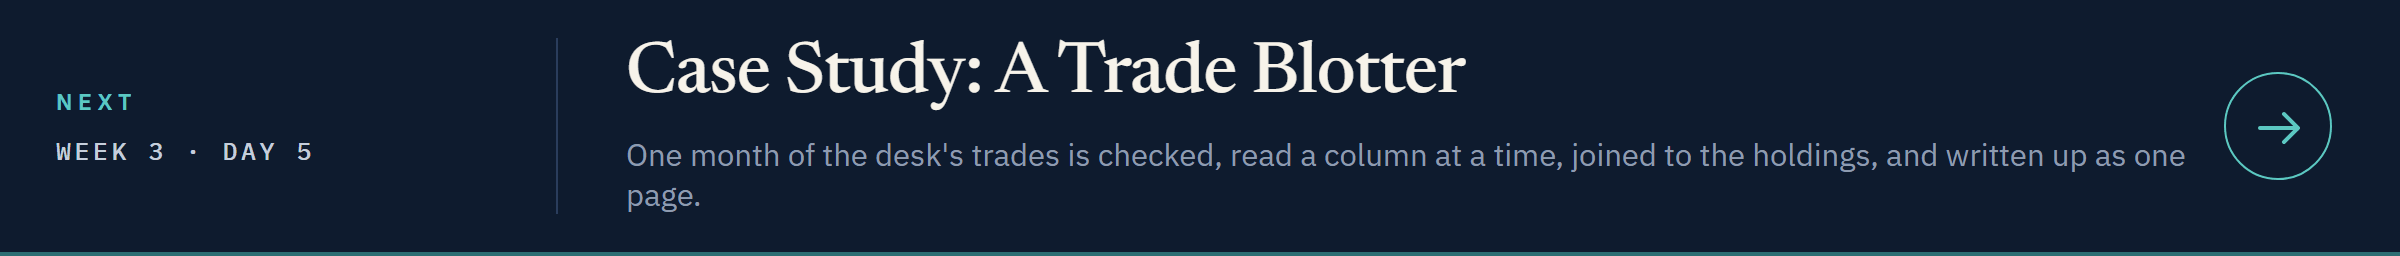](../day5/15_case_study_trade_blotter.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day5/15_case_study_trade_blotter.ipynb)